# BeanGuard: Bean Leaf Disease Classifier

**Goal:** a farmer uploads a photo of a bean leaf and the model says whether it is healthy or has a disease (angular leaf spot or bean rust).

**How to run this notebook**
- **On Kaggle:** attach the dataset *Bean Disease Dataset* (by therealoise) and run all cells. To push the results to GitHub at the end, add a Kaggle secret named `GITHUB_TOKEN` (see section 10).
- **On your laptop:** open it from the `notebook/` folder. The dataset is read from `data/raw_data/`.

## 1. Data reading and understanding
In this section we load the dataset and look at how it is organised.

In [ ]:
import os
import sys
import shutil
import json
import zipfile

ON_KAGGLE = os.path.exists("/kaggle/input")

if ON_KAGGLE:
    PROJECT_ROOT = "/kaggle/working/BeanGuardAI"
else:
    # on a laptop the project root is the folder that contains notebook/ and src/
    here = os.getcwd()
    PROJECT_ROOT = os.path.dirname(here) if os.path.basename(here) == "notebook" else here

# On Kaggle, get the repository first. The token is stored in Kaggle Secrets and never written in the notebook.
if ON_KAGGLE and not os.path.exists(os.path.join(PROJECT_ROOT, ".git")):
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    !git clone https://{token}@github.com/Jonathan2055/BeanGuardAI.git "{PROJECT_ROOT}"
    !git -C "{PROJECT_ROOT}" remote set-url origin https://github.com/Jonathan2055/BeanGuardAI.git

# Work from the project root, so %%writefile src/... creates the files in the right place.
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

print("Running on:", "Kaggle" if ON_KAGGLE else "laptop")
print("Project root:", os.getcwd())

In [2]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

### 1.1 Getting the dataset

**Source:** [Bean Disease Dataset on Kaggle](https://www.kaggle.com/datasets/therealoise/bean-disease-dataset), real photos of bean leaves in 3 classes: `healthy`, `angular_leaf_spot` and `bean_rust`.

The next cell finds the dataset automatically:
- **On Kaggle:** attach the dataset to the notebook. It is read directly from `/kaggle/input/` (read-only).
- **On your laptop:** it uses the folder `data/raw_data/`. If the dataset is not there yet, the cell unzips `data/raw_data/archive.zip`, or downloads it with `kagglehub` (`pip install kagglehub`).

In [ ]:
# Where is the raw dataset?
if ON_KAGGLE:
    RAW_DIR = "/kaggle/input/datasets/therealoise/bean-disease-dataset"   # attached dataset (read-only)
else:
    RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw_data")

DATA_DIR = os.path.join(PROJECT_ROOT, "data")
DATASET_DIR = os.path.join(RAW_DIR, "Bean_Dataset")

# On a laptop, if the dataset is not there yet: unzip archive.zip, or download it from Kaggle.
if not ON_KAGGLE and not os.path.isdir(DATASET_DIR):
    os.makedirs(RAW_DIR, exist_ok=True)
    zip_path = os.path.join(RAW_DIR, "archive.zip")
    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(RAW_DIR)
    else:
        import kagglehub
        shutil.copytree(kagglehub.dataset_download("therealoise/bean-disease-dataset"), RAW_DIR, dirs_exist_ok=True)

print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", os.path.exists(DATASET_DIR))

In [4]:
# The dataset is already attached in Kaggle, so read it directly.
# On your laptop, this reads the extracted dataset from the local RAW_DIR set above.

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}. "
        "Attach the dataset in Kaggle or update RAW_DIR for your laptop."
    )

for folder, sub_folders, files in os.walk(RAW_DIR):
    print(folder, "->", len(sub_folders), "folders,", len(files), "files")


/kaggle/input/datasets/therealoise/bean-disease-dataset -> 1 folders, 0 files
/kaggle/input/datasets/therealoise/bean-disease-dataset/Bean_Dataset -> 3 folders, 0 files
/kaggle/input/datasets/therealoise/bean-disease-dataset/Bean_Dataset/angular_leaf_spot -> 0 folders, 330 files
/kaggle/input/datasets/therealoise/bean-disease-dataset/Bean_Dataset/bean_rust -> 0 folders, 330 files
/kaggle/input/datasets/therealoise/bean-disease-dataset/Bean_Dataset/healthy -> 0 folders, 330 files


### 1.2 Classes and number of images

The folder name is the label of every image inside it. we are going to list the classes and count the images in each one.

In [5]:
DATASET_DIR = os.path.join(RAW_DIR, "Bean_Dataset")
class_names = sorted(os.listdir(DATASET_DIR))
print("Classes:", class_names)

counts = {}
for class_name in class_names:
    counts[class_name] = len(os.listdir(os.path.join(DATASET_DIR, class_name)))

counts_table = pd.DataFrame({"images": counts})
counts_table

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


,images
angular_leaf_spot,330
bean_rust,330
healthy,330


**Interpretation:**

This table counts how many image files are available in each class folder. The class folder names become the labels that the model will learn to predict. In this dataset, each class should contain 330 images, giving 990 images in total. Equal counts mean that no class is over-represented at the start of the project.



### 1.3 What do the leaves look like?

Five random images from each class.

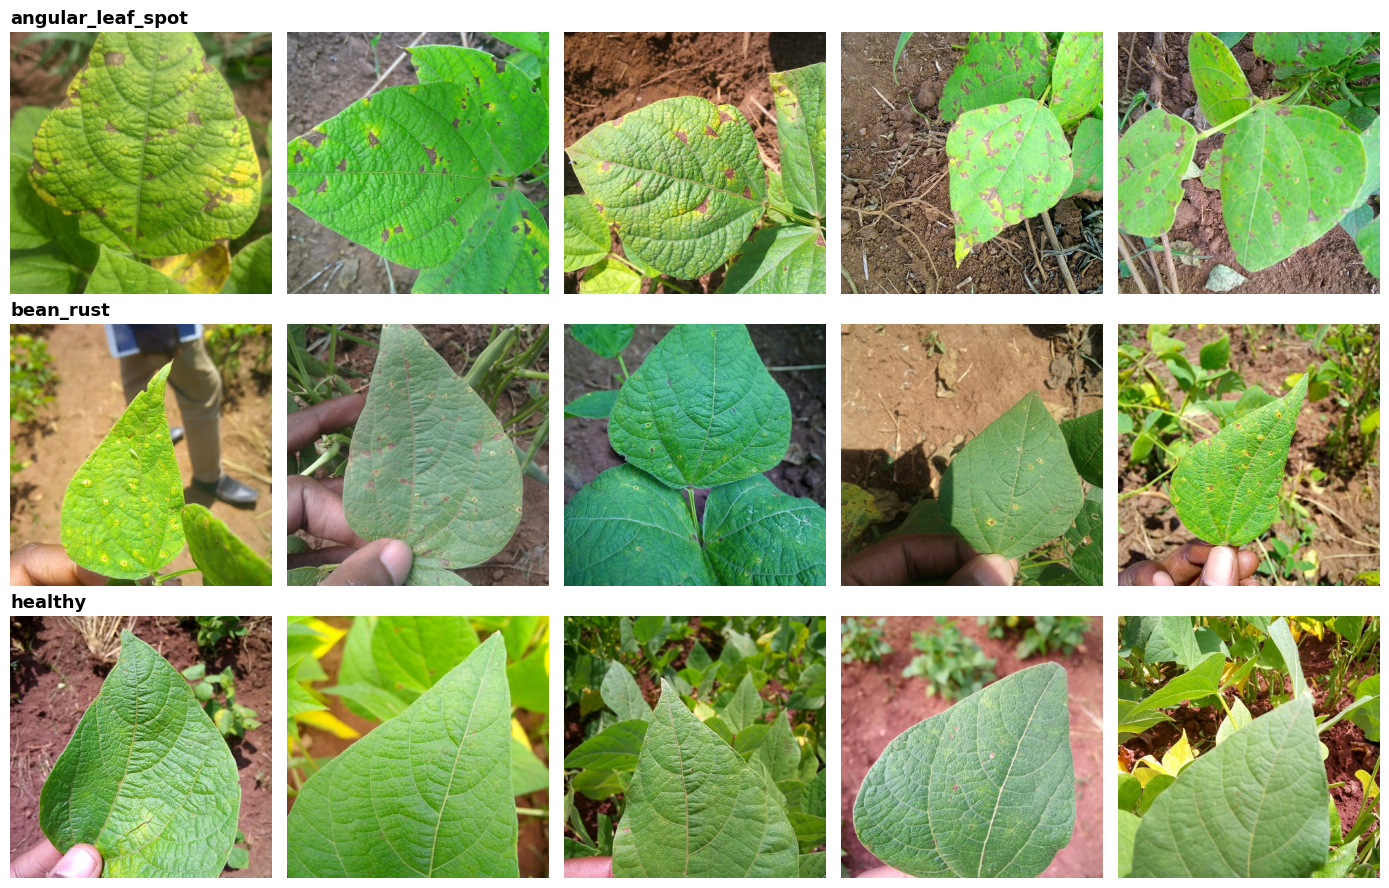

In [6]:
import random
random.seed(42)

fig, axes = plt.subplots(len(class_names), 5, figsize=(14, 9))

for row, class_name in enumerate(class_names):
    folder = os.path.join(DATASET_DIR, class_name)
    chosen = random.sample(os.listdir(folder), 5)
    for col, filename in enumerate(chosen):
        axes[row, col].imshow(Image.open(os.path.join(folder, filename)))
        axes[row, col].axis("off")
    axes[row, 0].set_title(class_name, loc="left", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretation:**

The image grid lets us inspect real examples from every class before training. Compare the visible leaf patterns: healthy leaves should look mostly green, angular leaf spot may show angular brown lesions and yellow areas, and bean rust may show many small rust-coloured spots. These are visual observations; individual photos can vary because of lighting, camera angle and background.



### 1.4 Image properties

The model needs images of one fixed size, so we check the size, colour mode and file format of every image.

In [7]:
rows = []
for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    for filename in os.listdir(folder):
        image = Image.open(os.path.join(folder, filename))
        rows.append({"class": class_name, "width": image.size[0], "height": image.size[1],
                     "mode": image.mode, "format": image.format})

image_info = pd.DataFrame(rows)

print("Different sizes found:")
print(image_info[["width", "height"]].drop_duplicates().to_string(index=False))
print("\nColour modes:\n", image_info["mode"].value_counts().to_string())
print("\nFile formats:\n", image_info["format"].value_counts().to_string())

Different sizes found:
 width  height
   500     500

Colour modes:
 mode
RGB    990

File formats:
 format
JPEG    990


**Interpretation:**

This cell checks the technical properties of every image: width, height, colour mode and file format. Consistent image properties make preprocessing easier. The dataset observations recorded below show that the images are 500 × 500, RGB and JPEG, so we only need to resize them to the input size required by the model.



### 1.5 What I observe

**each class has exactly 330 images** (990 in total), so the dataset is perfectly balanced. another thing is **all images are 500 x 500 pixels, RGB, JPEG**. No conversion is needed, we only have to resize them for the model later. also **Angular leaf spot:** brown, angular spots that are often surrounded by yellow patches, and some leaves are turning *yellow* while **Bean rust:** the signs are subtler, with many small pale or rusty dots on a mostly green leaf. I think this will probably be the hardest class for the model also **Healthy:** an even green leaf with clear veins and no spots.

**Photo conditions:** this images are real field photos, with soil, other plants and hands in the background. The diseased leaves are often photographed against bare soil, while healthy leaves more often fill the frame or sit among green plants. The model could learn these backgrounds instead of the disease, so we will use data augmentation to reduce that risk.

## 2. Data cleaning

Before training we check for two problems:
1. **Broken images** that cannot be opened.
2. **Duplicate images.** If the same photo ends up in both the training set and the test set, the model has already "seen the answer" and the test score looks better than it really is (this is called *data leakage*).

To find duplicates we compute a fingerprint (MD5 hash) of every file. Identical files always have the same fingerprint.
We do not delete anything from the raw folder. We only build a list of the good images to use.

In [8]:
import hashlib

seen = {}                # fingerprint -the first file that had it
broken_files = []
duplicate_files = []     # pairs of (duplicate, original)

for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    for filename in sorted(os.listdir(folder)):
        path = os.path.join(folder, filename)

        # can the image be opened?
        try:
            Image.open(path).verify()
        except Exception:
            broken_files.append(path)
            continue

        # have we already seen a file with exactly the same content?
        with open(path, "rb") as f:
            fingerprint = hashlib.md5(f.read()).hexdigest()
        if fingerprint in seen:
            duplicate_files.append((path, seen[fingerprint]))
        else:
            seen[fingerprint] = path

print("Broken images:   ", len(broken_files))
print("Exact duplicates:", len(duplicate_files))
for duplicate, original in duplicate_files[:10]:
    print("  ", duplicate, "is the same as", original)

Broken images:    0
Exact duplicates: 0


In [9]:
bad_paths = set(broken_files) | {duplicate for duplicate, original in duplicate_files}

clean_images = {}        # class name -> list of good image paths
for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    paths = [os.path.join(folder, f) for f in sorted(os.listdir(folder))]
    clean_images[class_name] = [p for p in paths if p not in bad_paths]

pd.DataFrame({"before cleaning": counts,
              "after cleaning": {c: len(v) for c, v in clean_images.items()}})

,before cleaning,after cleaning
angular_leaf_spot,330,330
bean_rust,330,330
healthy,330,330


**Interpretation:**

The code removes broken and duplicate file paths from the lists that will be used for training. It does not delete the original image files. This protects the experiment from unreadable files and exact duplicate images appearing in different data splits. The next Markdown cell reports how many files were found and kept.



### Cleaning result
We found 0 broken images and 0 exact duplicates, so all 330 images in each class are kept (990 in total).

## 3. Splitting the data
**Train (70%)** for the model to learns from these images , **Validation (15%)** which will be used *during* training to tune the model and stop at the right time and **Test (15%)** used **once at the end** to measure how good the model really is on unseen images

We split **each class separately**, so train, validation and test all contain the same share of every class. We shuffle first so the split is random, and we fix the random seed so we get the same split every time.

In [10]:
import json
import random

TRAIN_SIZE = 0.70
VAL_SIZE = 0.15        # the test set gets everything that is left (about 15%)
SEED = 42

random.seed(SEED)
split_files = {"train": [], "val": [], "test": []}    # each item is (image path, class name)

for class_name in class_names:
    files = clean_images[class_name][:]               # copy of the list
    random.shuffle(files)

    n = len(files)
    n_train = int(n * TRAIN_SIZE)
    n_val = int(n * VAL_SIZE)

    split_files["train"] += [(p, class_name) for p in files[:n_train]]
    split_files["val"] += [(p, class_name) for p in files[n_train:n_train + n_val]]
    split_files["test"] += [(p, class_name) for p in files[n_train + n_val:]]

for split, items in split_files.items():
    print(split, ":", len(items), "images")

train : 690 images
val : 147 images
test : 153 images


**Interpretation:**

The code shuffles the images separately inside each class, then assigns 70% to training, 15% to validation and the remaining images to testing. Splitting each class separately keeps the class proportions similar across all three groups. The fixed random seed (`42`) makes the split repeatable when the same dataset is used.



**Safety check:** no image may appear in more than one split, otherwise we would have data leakage.

In [11]:
paths = {split: {path for path, class_name in items} for split, items in split_files.items()}

print("train & val overlap :", len(paths["train"] & paths["val"]))
print("train & test overlap:", len(paths["train"] & paths["test"]))
print("val & test overlap  :", len(paths["val"] & paths["test"]))

train & val overlap : 0
train & test overlap: 0
val & test overlap  : 0


**Interpretation:**

Each printed overlap should be `0`. This means that no exact image path appears in two different splits. If any overlap is greater than zero, the same image could be used for learning and evaluation, which would make the evaluation score too optimistic. Continue only when all three overlap counts are zero.



### Copy the images into data/train, data/val and data/test

Each split gets one sub-folder per class, which is the layout the model will read from. We also save the class names so the model and the API always use the same label order. The raw data is not touched.

In [12]:
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# start fresh each time we run this cell (we only delete train / val / test)
for split in ["train", "val", "test"]:
    shutil.rmtree(os.path.join(DATA_DIR, split), ignore_errors=True)

for split, items in split_files.items():
    for path, class_name in items:
        destination = os.path.join(DATA_DIR, split, class_name)
        os.makedirs(destination, exist_ok=True)
        shutil.copy(path, destination)

with open(os.path.join(DATA_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

# check what we created
rows = []
for class_name in class_names:
    row = {"class": class_name}
    for split in ["train", "val", "test"]:
        row[split] = len(os.listdir(os.path.join(DATA_DIR, split, class_name)))
    rows.append(row)

split_table = pd.DataFrame(rows).set_index("class")
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()
split_table

,train,val,test,total
class,,,,
angular_leaf_spot,230,49,51,330
bean_rust,230,49,51,330
healthy,230,49,51,330
TOTAL,690,147,153,990


**Interpretation:**

This cell copies the selected images into the project folders `data/train`, `data/val` and `data/test`, with one subfolder for each class. It also writes `data/class_names.json`, which preserves the class order used by the model and prediction code. Only the split folders are recreated; the original dataset in the Kaggle input folder is not changed.



## 4. Data visualizations
the features we are going to measure are **Class balance** across the train / validation / test sets, **Colour** (average red, green and blue value of each image) and **Brightness** of the images

### 4.1 Class balance across the splits

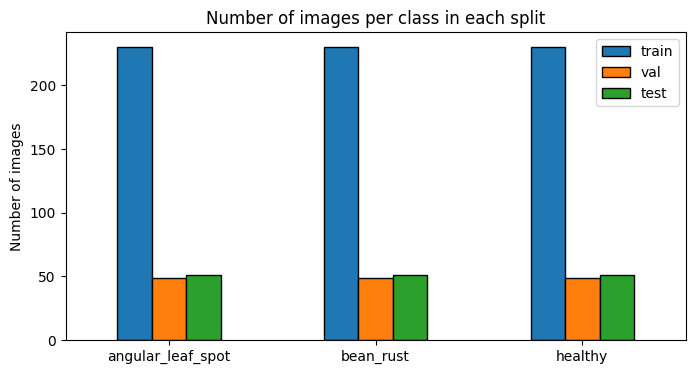

In [13]:
split_table.drop("TOTAL")[["train", "val", "test"]].plot(kind="bar", figsize=(8, 4), edgecolor="black")
plt.title("Number of images per class in each split")
plt.ylabel("Number of images")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Interpretation:**

The classes are **perfectly balanced**: every class has 230 training, 49 validation and 51 test images. The three splits have different sizes on purpose (70% / 15% / 15%), and the small difference between 49 and 51 comes only from rounding, the same for every class. Because no class is bigger than the others, the model cannot get a good score just by favouring one class, so **accuracy is a fair metric** here. We will still report precision, recall and F1 for each class, to see which disease the model finds hardest. The test set is small (51 images per class), so one wrong image changes a class score by about 2 percentage points. We should not read too much into small differences.

### 4.2 Colour and brightness of the images

Diseased leaves have spots and yellowing, so we expect their colours to differ from healthy leaves. For every image we compute the average **red**, **green** and **blue** value (0 to 255) and the average **brightness**. We shrink each image to 64 x 64 first, only to make this faster.

In [14]:
stats = []

for split, items in split_files.items():
    for path, class_name in items:
        image = Image.open(path).convert("RGB")
        small = np.array(image.resize((64, 64)))        # a 64 x 64 x 3 table of numbers

        stats.append({
            "class": class_name,
            "split": split,
            "red": small[:, :, 0].mean(),
            "green": small[:, :, 1].mean(),
            "blue": small[:, :, 2].mean(),
            "brightness": small.mean(),
        })

stats = pd.DataFrame(stats)
stats.groupby("class")[["red", "green", "blue", "brightness"]].mean().round(1)

,red,green,blue,brightness
class,,,,
angular_leaf_spot,129.2,134.9,73.9,112.7
bean_rust,119.8,119.6,77.1,105.5
healthy,122.3,142.8,87.5,117.5


#### Average colour per class

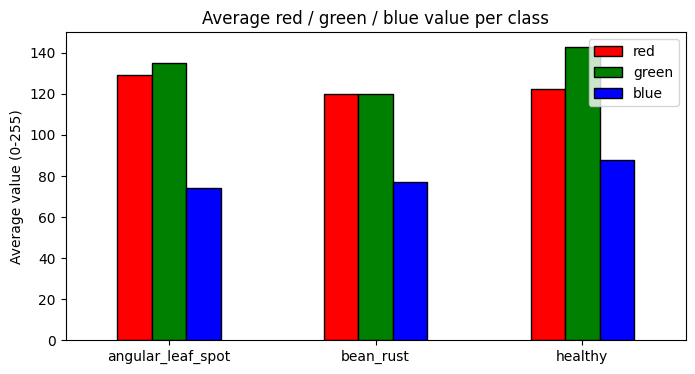

In [15]:
colour_means = stats.groupby("class")[["red", "green", "blue"]].mean()

colour_means.plot(kind="bar", figsize=(8, 4), color=["red", "green", "blue"], edgecolor="black")
plt.title("Average red / green / blue value per class")
plt.ylabel("Average value (0-255)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Interpretation**

**Healthy** leaves have the highest green (142.8) and the highest blue (87.5), and their green is clearly higher than their red (122.3). They look like an even, fresh green leaf. **Bean rust** has the lowest green (119.6): red and green are almost equal (119.8 vs 119.6), which gives a duller, yellow-brown tone. This matches the small rusty dots on the leaves. **Angular leaf spot** has the highest red (129.2) and the lowest blue (73.9). Brown spots and yellowing leaves are made of red and green with little blue, which fits what we saw in the photos.

The differences are only about 5 to 20 points out of 255, so **colour helps but cannot separate the classes alone**. The model also has to learn texture and shape (spots, veins).

Caution: the averages include the background. Red soil in the photos could raise the red value, so part of this difference may come from the background and not from the leaf.

#### Brightness per class

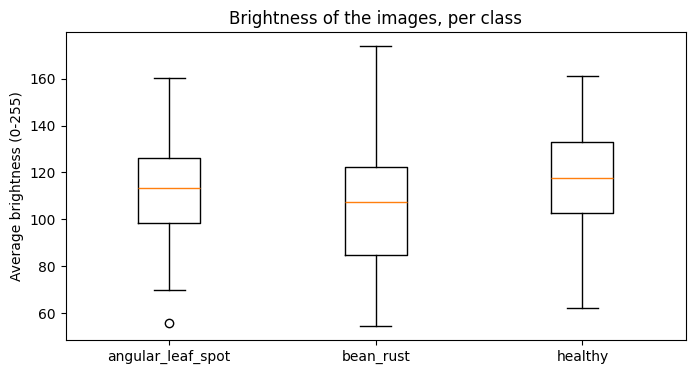

In [16]:
data = [stats[stats["class"] == c]["brightness"] for c in class_names]

plt.figure(figsize=(8, 4))
plt.boxplot(data)
plt.xticks(range(1, len(class_names) + 1), class_names)
plt.title("Brightness of the images, per class")
plt.ylabel("Average brightness (0-255)")
plt.show()

**Interpretation:**

The boxes overlap a lot. The median brightness is similar for all three classes (about 113 for angular leaf spot, 107 for bean rust and 118 for healthy), so **brightness alone cannot tell the classes apart**. That is good news, because the model cannot cheat by learning which class has brighter photos. Another thing inside every class the brightness varies a lot (from about 55 to 175), because some photos were taken in strong sun and others in shade. Bean rust varies the most.

A farmer's phone photos will have the same problem (sun, shade, cloudy days). So we will use **data augmentation** (random brightness and contrast changes, flips, rotations) when training, so the model learns to recognise the disease in any light.

## 5. Preparing the images for the model

The model needs:
1. every image resized to the **same size** (224 x 224)
2. images delivered in **batches** (32 at a time)
3. **data augmentation** during training (random flips, rotations, zoom, contrast)

We write this code into the files in `src/`, so that the notebook, the retraining code, the API and the UI all use **exactly the same preprocessing**. In the notebook we use `%%writefile` to save a cell as a `.py` file.

In [17]:
import sys
import tensorflow as tf

In [19]:
%load_ext autoreload
%autoreload 2

# PROJECT_ROOT is the repository folder on both Kaggle and your laptop.
sys.path.insert(0, PROJECT_ROOT)


In [ ]:
import os

# Create the folders used by the notebook and generated Python files.
os.makedirs(os.path.join(PROJECT_ROOT, "src"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_ROOT, "data"), exist_ok=True)


**Interpretation:**

These commands make sure the project has the folders needed by the notebook. `src/` stores the Python modules created by the `%%writefile` cells, `data/` stores the split images and class-name file, and `models/` will store the trained model and its evaluation metrics. `exist_ok=True` means the cell can be run again without failing if a folder already exists.



In [21]:
%%writefile src/__init__.py
# makes src a Python package

Overwriting src/__init__.py


**Interpretation:**

This creates `src/__init__.py`. It marks `src` as a Python package, allowing later notebook cells and other project files to import modules using paths such as `from src import config`.



### 5.1 `src/config.py`: settings in one place
Paths and sizes are defined once here. The paths are built from the location of the file itself, so they work whether the code is started from the notebook, the API or Docker.

In [ ]:
%%writefile src/config.py
"""Settings shared by the notebook, the retraining code, the API and the UI."""
import json
from pathlib import Path

# Project root = the folder that contains src/
# BASE_DIR is detected from this file, so it works on Kaggle, on your laptop and in Docker.
BASE_DIR = Path(__file__).resolve().parent.parent

DATA_DIR = BASE_DIR / "data"
UPLOADS_DIR = DATA_DIR / "uploads"
MODELS_DIR = BASE_DIR / "models"                     # saved models and evaluation metrics
MODEL_PATH = MODELS_DIR / "bean_model.keras"         # full model: used by the API and for retraining
MODEL_H5_PATH = MODELS_DIR / "bean_model.h5"         # inference-only copy (no augmentation)

IMG_SIZE = (224, 224)     # every image is resized to 224 x 224
BATCH_SIZE = 32           # the model looks at 32 images at a time


def load_class_names():
    """The class order saved in data/class_names.json by the notebook."""
    with open(DATA_DIR / "class_names.json") as f:
        return json.load(f)

**Interpretation:**

This file centralises the paths and image settings used by the project. `BASE_DIR` finds the project root based on the location of `src/config.py`, so the project can be moved between Kaggle, a laptop and Docker without rewriting every path. Two model files are defined: `MODEL_PATH` (`models/bean_model.keras`) is the full model used by the API and for retraining, and `MODEL_H5_PATH` (`models/bean_model.h5`) is an inference-only copy. `load_class_names()` reads the saved class order from `data/class_names.json`.

### 5.2 `src/preprocessing.py`: the preprocessing functions

**Function and What they do:**
1. `list_images` : lists the image paths and labels in a folder like `data/train` 
2. `make_dataset` : reads, decodes and resizes the images and groups them into batches 
3. `build_augmentation` : random flip, rotation, zoom and contrast (only used while training) 
4. `validate_image` : checks that an uploaded file is a real image (used by the API) 
5. `image_to_array` : prepares ONE uploaded image for prediction, resized exactly like in training 

In [23]:
%%writefile src/preprocessing.py
"""Preprocessing: turning image files into data the model can use."""
import io
import os

import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

from src.config import BATCH_SIZE, IMG_SIZE

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def list_images(folder, class_names):
    """Return two lists: image paths and their label numbers (0, 1, 2).
    Expects the layout:  folder/<class_name>/<image files>"""
    paths, labels = [], []
    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        if not os.path.isdir(class_folder):
            continue
        for filename in sorted(os.listdir(class_folder)):
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                paths.append(os.path.join(class_folder, filename))
                labels.append(label)
    return paths, labels


def load_and_resize(path, label):
    """Read one image file, decode it and resize it to 224 x 224 (values stay 0-255)."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label


def make_dataset(paths, labels, shuffle=False):
    """Turn lists of paths and labels into batches the model can read."""
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(len(paths), seed=42)
    dataset = dataset.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def build_augmentation():
    """Random changes applied to training images. Only active during training."""
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name="augmentation")


def validate_image(file_bytes):
    """Check that uploaded bytes are a real image. Returns a PIL image or raises ValueError."""
    try:
        Image.open(io.BytesIO(file_bytes)).verify()
        return Image.open(io.BytesIO(file_bytes)).convert("RGB")
    except Exception:
        raise ValueError("The file is not a valid image (use .jpg or .png).")


def image_to_array(pil_image):
    """PIL image -> array of shape (1, 224, 224, 3), resized the same way as in training."""
    array = np.asarray(pil_image, dtype=np.float32)
    array = tf.image.resize(array, IMG_SIZE).numpy()
    return np.expand_dims(array, axis=0)

Overwriting src/preprocessing.py


**Interpretation:**

This file contains reusable image-preparation functions. `list_images` collects image paths and numeric labels; `make_dataset` reads, resizes, batches and prefetches images; `build_augmentation` creates random image changes for training; and the upload helper functions prepare and validate a single image for prediction. Keeping these steps in one module helps the notebook and future application use the same preprocessing.



### 5.3 Using our own functions in the notebook
We import the functions we just saved and load the three splits as batches. The validation and test sets are not shuffled, so the predictions stay in the same order as the labels.

In [24]:
from src import config
from src.preprocessing import list_images, make_dataset, build_augmentation

class_names = config.load_class_names()
print("Classes:", class_names)

train_paths, train_labels = list_images(config.DATA_DIR / "train", class_names)
val_paths, val_labels = list_images(config.DATA_DIR / "val", class_names)
test_paths, test_labels = list_images(config.DATA_DIR / "test", class_names)
print("Images:", len(train_paths), "train,", len(val_paths), "val,", len(test_paths), "test")

train_ds = make_dataset(train_paths, train_labels, shuffle=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

# look at one batch
for images, labels in train_ds.take(1):
    print("Batch of images:", images.shape)
    print("Batch of labels:", labels.shape)
    print("Pixel values from", images.numpy().min(), "to", images.numpy().max())

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Images: 690 train, 147 val, 153 test
Batch of images: (32, 224, 224, 3)
Batch of labels: (32,)
Pixel values from 0.0 to 255.0


**Interpretation:**

The notebook imports the settings and preprocessing functions that were just written to `src/`. It then loads the class names and creates three TensorFlow datasets. Training data is shuffled, while validation and test data keep a stable order so that predictions can be compared with the correct labels. The printed batch shapes should show batches of images with three colour channels and matching label values.



### 5.4 Data augmentation
During training the model sees a slightly different version of each photo every epoch: flipped, rotated, zoomed, with changed contrast. It cannot just memorise the training photos, and it learns to recognise the disease in different lighting and angles, like the real photos a farmer will take. Augmentation is never used when predicting.

Here is one leaf, augmented 8 different ways:

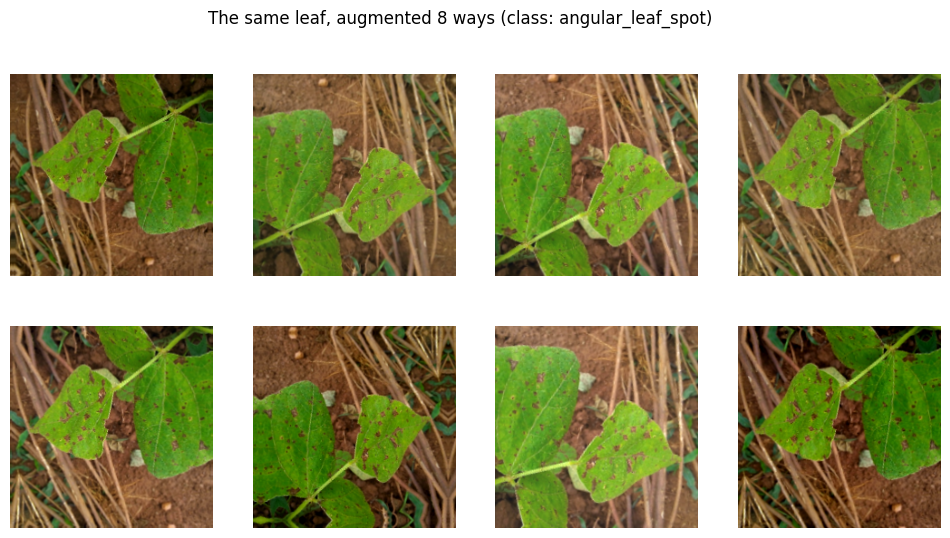

In [25]:
augmentation = build_augmentation()

for images, labels in train_ds.take(1):
    plt.figure(figsize=(12, 6))
    for i in range(8):
        augmented = augmentation(images[:1], training=True)[0].numpy()
        plt.subplot(2, 4, i + 1)
        plt.imshow(np.clip(augmented, 0, 255).astype("uint8"))
        plt.axis("off")
    plt.suptitle("The same leaf, augmented 8 ways (class: " + class_names[int(labels[0])] + ")")
    plt.show()

**Interpretation:**

The grid shows eight altered versions of one training image. These changes are generated randomly, so the same original image can look slightly different each time it is passed through training. This helps the model learn disease patterns that remain useful when a farmer takes a photo from a different angle or under different lighting. Augmentation is only active during training, not prediction.



## 6. Modelling

We build two models and compare them:
1. a **baseline CNN** trained from scratch: simple, with no tricks
2. the **main model**: transfer learning with MobileNetV2, plus optimization techniques

### 6.1 `src/model.py`: evaluation functions
We save the evaluation code into `src/model.py` now, so the retraining code can reuse it later.

- **Accuracy:** the share of images predicted correctly
- **Loss:** how wrong the predicted probabilities are (lower is better)
- **Precision:** when the model says "rust", how often is it really rust?
- **Recall:** of all the real rust leaves, how many did the model find?
- **F1:** one number combining precision and recall

With 3 classes we use the **macro average**: compute each score per class, then average them, so every class counts equally.

In [26]:
%%writefile src/model.py
"""Model: evaluation functions (more functions are added in the next step)."""
import numpy as np


def predict_all(model, dataset):
    """Predict every image in a dataset. Returns the true labels and the predicted labels."""
    y_true = np.concatenate([labels.numpy() for images, labels in dataset])
    y_pred = np.argmax(model.predict(dataset, verbose=0), axis=1)
    return y_true, y_pred


def evaluate_model(model, dataset, class_names):
    """Loss, accuracy, macro precision / recall / F1, per-class F1 and the confusion matrix."""
    loss, accuracy = model.evaluate(dataset, verbose=0)
    y_true, y_pred = predict_all(model, dataset)

    n = len(class_names)
    matrix = np.zeros((n, n), dtype=int)       # rows = true class, columns = predicted class
    for true, predicted in zip(y_true, y_pred):
        matrix[true, predicted] += 1

    true_positives = np.diag(matrix)
    predicted_totals = matrix.sum(axis=0)
    actual_totals = matrix.sum(axis=1)
    precision = np.divide(true_positives, predicted_totals, out=np.zeros(n), where=predicted_totals > 0)
    recall = np.divide(true_positives, actual_totals, out=np.zeros(n), where=actual_totals > 0)
    both = precision + recall
    f1 = np.divide(2 * precision * recall, both, out=np.zeros(n), where=both > 0)

    return {
        "loss": round(float(loss), 4),
        "accuracy": round(float(accuracy), 4),
        "precision": round(float(precision.mean()), 4),
        "recall": round(float(recall.mean()), 4),
        "f1": round(float(f1.mean()), 4),
        "per_class_f1": {name: round(float(v), 4) for name, v in zip(class_names, f1)},
        "confusion_matrix": matrix.tolist(),
        "images": int(len(y_true)),
    }

Overwriting src/model.py


**Interpretation:**

The functions in this file evaluate a model consistently. `predict_all` returns the correct labels and the model's predicted labels. `evaluate_model` calculates loss, accuracy, macro precision, macro recall, macro F1, per-class F1 and a confusion matrix. Macro averaging gives each of the three classes equal importance, rather than allowing a larger class to dominate the average.



### 6.2 Baseline CNN
Three blocks of convolution + pooling to find patterns, then a small dense layer that decides the class. No pre-training, no augmentation, no regularization, so this is a plain "vanilla" model.

In [27]:
from tensorflow import keras
from tensorflow.keras import layers
from src.model import evaluate_model

keras.utils.set_random_seed(42)       # makes the results repeatable

baseline = keras.Sequential([
    layers.Input(shape=config.IMG_SIZE + (3,)),
    layers.Rescaling(1 / 255),                              # pixel values 0-255 -> 0-1
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(class_names), activation="softmax"),   # one probability per class
], name="baseline_cnn")

baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,792,739 (10.65 MB)

 Trainable params: 2,792,739 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

**Interpretation:**

This cell builds the baseline CNN from scratch. Convolution layers learn visual patterns, pooling reduces the spatial size of the feature maps, and the dense layers use the learned features to choose among the three classes. The final softmax layer returns three class probabilities. This model is our simple reference point for comparing MobileNetV2.



In [28]:
baseline_run = baseline.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 16s 350ms/step - accuracy: 0.3986 - loss: 1.1390 - val_accuracy: 0.5034 - val_loss: 1.0228
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.5797 - loss: 0.8937 - val_accuracy: 0.5782 - val_loss: 0.9255
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.6739 - loss: 0.7464 - val_accuracy: 0.6939 - val_loss: 0.7547
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7551 - loss: 0.5897 - val_accuracy: 0.6667 - val_loss: 0.8256
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7986 - loss: 0.4955 - val_accuracy: 0.7279 - val_loss: 0.6829
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8377 - loss: 0.4143 - val_accuracy: 0.6803 - val_loss: 0.8129
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8797 - loss: 0.2955 - val_accuracy: 0.6871 - val_loss: 0.9271
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9130 - loss: 0.2441 - val_accuracy: 0.6667 -

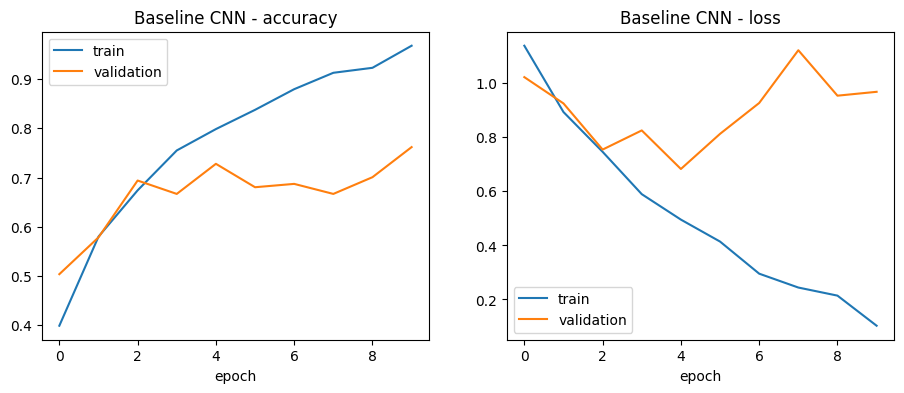

In [29]:
def plot_history(history, title):
    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="train")
    plt.plot(history["val_accuracy"], label="validation")
    plt.title(title + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="train")
    plt.plot(history["val_loss"], label="validation")
    plt.title(title + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.show()


plot_history(baseline_run.history, "Baseline CNN")

In [30]:
baseline_val = evaluate_model(baseline, val_ds, class_names)

print("Baseline CNN on the VALIDATION set:")
for name in ["loss", "accuracy", "precision", "recall", "f1"]:
    print(f"  {name:10s}: {baseline_val[name]}")

Baseline CNN on the VALIDATION set:
  loss      : 0.9685
  accuracy  : 0.7619
  precision : 0.7604
  recall    : 0.7619
  f1        : 0.7553


In [31]:
print("Per-class F1:", baseline_val["per_class_f1"])
print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(baseline_val["confusion_matrix"], index=class_names, columns=class_names))

Per-class F1: {'angular_leaf_spot': 0.7629, 'bean_rust': 0.6591, 'healthy': 0.844}

Confusion matrix (rows = true class, columns = predicted class):
                   angular_leaf_spot  bean_rust  healthy
angular_leaf_spot                 37          9        3
bean_rust                          9         29       11
healthy                            2          1       46


**Interpretation:**
- **The baseline learns, but it over-fits.** Training accuracy rises from 40% to 97% over 10 epochs, while validation accuracy stays between 67% and 76% from epoch 3 onwards and jumps up and down. The validation loss is lowest at epoch 5 (0.68), then climbs to 1.12 at epoch 8 while the training loss keeps falling to 0.10. The model is memorising the training photos. The final gap between training and validation accuracy is about 21 points.
- **76.2% is far above chance** (33% for 3 balanced classes), so the model learned real differences, but it still misclassifies about 1 in 4 validation leaves (35 of 147), which a farmer could not rely on.
- Precision (0.760), recall (0.762) and F1 (0.755) are close to the accuracy, because the classes are balanced.
- **Bean rust is the hardest class** (F1 0.659): 20 of the 49 rust leaves were misclassified (9 as angular leaf spot, 11 as healthy). Healthy is the easiest (F1 0.844, 46 of 49 correct).
- The last epoch jumped from 70% to 76% accuracy. With only 147 validation images, one image is 0.7 points, so part of this is luck.
- We expect transfer learning, augmentation and early stopping to reduce the over-fitting.

### 6.3 Main model: transfer learning with MobileNetV2

**Transfer learning** means we start from MobileNetV2, a network already trained on 1.4 million everyday images (ImageNet). It already knows how to see edges, textures and shapes. We only teach it our 3 bean classes. With only 690 training images, this works much better than training from zero.

**Optimization techniques we used:**

1. **Transfer learning** : start from the knowledge of MobileNetV2 
2. **Data augmentation** : random flips, rotation, zoom, brightness and contrast, so the model cannot memorise the photos 
3. **Dropout (0.3)** : randomly switches off 30% of neurons during training, which reduces over-fitting 
4. **L2 regularization** : penalises very large weights in the final layer 
5. **Adam optimizer** : learning rate 0.001 for the new layers, 0.00001 for fine-tuning 
6. **Early stopping** : stops when validation loss stops improving and returns to the best epoch 
7. **Learning-rate reduction** : halves the learning rate when progress stalls 
8. **Fine-tuning** : in phase 2, the top layers of MobileNetV2 adapt to bean leaves 

**Model structure:** image , augmentation , rescale , MobileNetV2 , average pooling , dropout , 3 probabilities

We train in two phases. **Phase 1:** MobileNetV2 stays frozen and only the new classification layer learns. **Phase 2:** we unfreeze the last layers of MobileNetV2 and fine-tune them with a very small learning rate.

In [ ]:
%%writefile src/model.py
"""Model: building, fine-tuning settings and evaluation."""
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from src.config import IMG_SIZE
from src.preprocessing import build_augmentation


def build_model(num_classes, pretrained=True):
    """MobileNetV2 (pre-trained on ImageNet) + a small new classification head.
    The model takes raw images (0-255): rescaling and augmentation are inside the model."""
    base = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,                                  # remove ImageNet's 1000-class output
        weights="imagenet" if pretrained else None,
    )
    base.trainable = False                                  # phase 1: keep the pre-trained knowledge

    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = build_augmentation()(inputs)                        # only active while training
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)           # 0-255 -> -1...1 (what MobileNetV2 expects)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax",
                           kernel_regularizer=regularizers.l2(1e-4))(x)
    return keras.Model(inputs, outputs, name="bean_leaf_classifier")


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def find_base(model):
    """Return the MobileNetV2 part of the model."""
    for layer in model.layers:
        if layer.name.startswith("mobilenetv2"):
            return layer
    raise ValueError("MobileNetV2 base not found in the model")


def unfreeze_top_layers(model, n_layers=30):
    """Fine-tuning: let the last n layers of MobileNetV2 learn (BatchNormalization stays frozen)."""
    base = find_base(model)
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def predict_all(model, dataset):
    """Predict every image in a dataset. Returns the true labels and the predicted labels."""
    y_true = np.concatenate([labels.numpy() for images, labels in dataset])
    y_pred = np.argmax(model.predict(dataset, verbose=0), axis=1)
    return y_true, y_pred


def evaluate_model(model, dataset, class_names):
    """Loss, accuracy, macro precision / recall / F1, per-class F1 and the confusion matrix."""
    loss, accuracy = model.evaluate(dataset, verbose=0)
    y_true, y_pred = predict_all(model, dataset)

    n = len(class_names)
    matrix = np.zeros((n, n), dtype=int)       # rows = true class, columns = predicted class
    for true, predicted in zip(y_true, y_pred):
        matrix[true, predicted] += 1

    true_positives = np.diag(matrix)
    predicted_totals = matrix.sum(axis=0)
    actual_totals = matrix.sum(axis=1)
    precision = np.divide(true_positives, predicted_totals, out=np.zeros(n), where=predicted_totals > 0)
    recall = np.divide(true_positives, actual_totals, out=np.zeros(n), where=actual_totals > 0)
    both = precision + recall
    f1 = np.divide(2 * precision * recall, both, out=np.zeros(n), where=both > 0)

    return {
        "loss": round(float(loss), 4),
        "accuracy": round(float(accuracy), 4),
        "precision": round(float(precision.mean()), 4),
        "recall": round(float(recall.mean()), 4),
        "f1": round(float(f1.mean()), 4),
        "per_class_f1": {name: round(float(v), 4) for name, v in zip(class_names, f1)},
        "confusion_matrix": matrix.tolist(),
        "images": int(len(y_true)),
    }


def export_inference_model(trained_model):
    """The same model WITHOUT the augmentation block (augmentation is only needed while training).
    Used to create the .h5 file: the RandomBrightness layer cannot be saved in .h5 format."""
    inputs = keras.Input(shape=trained_model.input_shape[1:])
    x = inputs
    for layer in trained_model.layers[2:]:        # skip the InputLayer and the augmentation block
        x = layer(x)
    return keras.Model(inputs, x, name="bean_leaf_inference")


In [33]:
from src.model import build_model, compile_model, unfreeze_top_layers, find_base

keras.utils.set_random_seed(42)

model = build_model(len(class_names))
compile_model(model, 1e-3)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "bean_leaf_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Interpretation:**

This creates the main MobileNetV2 model and prints its layer structure. The pre-trained MobileNetV2 feature extractor is initially frozen, while the new classification head learns to distinguish the three bean-leaf classes. The model is compiled with a learning rate of `0.001` for the first training phase. The following phase-1 cell trains the new layers.



#### Phase 1: train only the new layers
MobileNetV2 stays frozen. We stop early when the validation loss has not improved for 3 epochs, and go back to the best epoch.

In [34]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

phase1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - accuracy: 0.4667 - loss: 1.1510 - val_accuracy: 0.7007 - val_loss: 0.6957 - learning_rate: 0.0010
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.7159 - loss: 0.6769 - val_accuracy: 0.7755 - val_loss: 0.5314 - learning_rate: 0.0010
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.7565 - loss: 0.5545 - val_accuracy: 0.7823 - val_loss: 0.4765 - learning_rate: 0.0010
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.7971 - loss: 0.5035 - val_accuracy: 0.8231 - val_loss: 0.4406 - learning_rate: 0.0010
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.8304 - loss: 0.4553 - val_accuracy: 0.8367 - val_loss: 0.4069 - learning_rate: 0.0010
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8333 - loss: 0.4264 - val_accuracy: 0.8299 - val_loss: 0.4042 - learning_rate: 0.0010
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.8435 - loss: 0.4268 - val_ac

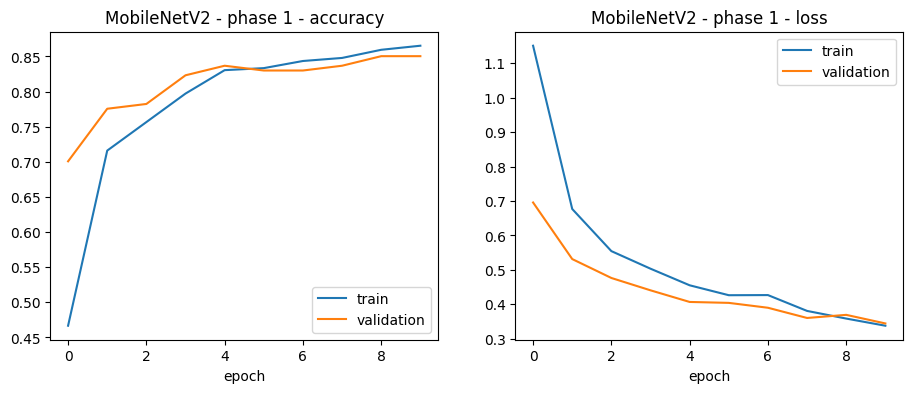

MobileNetV2 (phase 1) on the VALIDATION set:
  loss      : 0.3445
  accuracy  : 0.8503
  precision : 0.8483
  recall    : 0.8503
  f1        : 0.8481


In [35]:
plot_history(phase1.history, "MobileNetV2 - phase 1")

phase1_val = evaluate_model(model, val_ds, class_names)
print("MobileNetV2 (phase 1) on the VALIDATION set:")
for name in ["loss", "accuracy", "precision", "recall", "f1"]:
    print(f"  {name:10s}: {phase1_val[name]}")

**Interpretation:**
- **Transfer learning beats the baseline.** Validation accuracy rose from 76.2% to 85.0% (125 of 147 correct instead of 112), F1 from 0.755 to 0.848, and validation loss from 0.969 to 0.345. Even in the first epoch the model already reached 70% validation accuracy, because MobileNetV2 already knows how to see textures and shapes.
- **No over-fitting.** At epoch 10 training accuracy is 86.5% and validation accuracy 85.0%, and the curves go down and up together. Training scores are measured with augmentation and dropout switched on, which makes them slightly harder than validation.
- **The model had not finished learning.** The validation loss was still falling at epoch 10 and the learning rate was never reduced, so early stopping did not trigger. This is why we continue with phase 2 (fine-tuning).

In [36]:
phase1_weights = model.get_weights()        # a backup of the best phase 1 model

unfreeze_top_layers(model, n_layers=30)
compile_model(model, 1e-5)                  # must compile again after changing what is trainable

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

phase2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - accuracy: 0.8754 - loss: 0.3236 - val_accuracy: 0.8639 - val_loss: 0.3157 - learning_rate: 1.0000e-05
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9043 - loss: 0.2670 - val_accuracy: 0.8571 - val_loss: 0.3005 - learning_rate: 1.0000e-05
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.8899 - loss: 0.2893 - val_accuracy: 0.8435 - val_loss: 0.3373 - learning_rate: 1.0000e-05
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.8913 - loss: 0.2458 - val_accuracy: 0.8707 - val_loss: 0.2854 - learning_rate: 1.0000e-05
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.9116 - loss: 0.2420 - val_accuracy: 0.8639 - val_loss: 0.2918 - learning_rate: 1.0000e-05
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9246 - loss: 0.2084 - val_accuracy: 0.8707 - val_loss: 0.2605 - learning_rate: 1.0000e-05
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9145

In [ ]:
phase2_val = evaluate_model(model, val_ds, class_names)

if phase2_val["loss"] < phase1_val["loss"]:
    print("Phase 2 is better, we keep the fine-tuned model.")
    final_val = phase2_val
else:
    print("Phase 2 is not better, we go back to the phase 1 model.")
    model.set_weights(phase1_weights)
    final_val = phase1_val

print("\nFinal model on the VALIDATION set:")
for name in ["loss", "accuracy", "precision", "recall", "f1"]:
    print(f"  {name:10s}: {final_val[name]}")

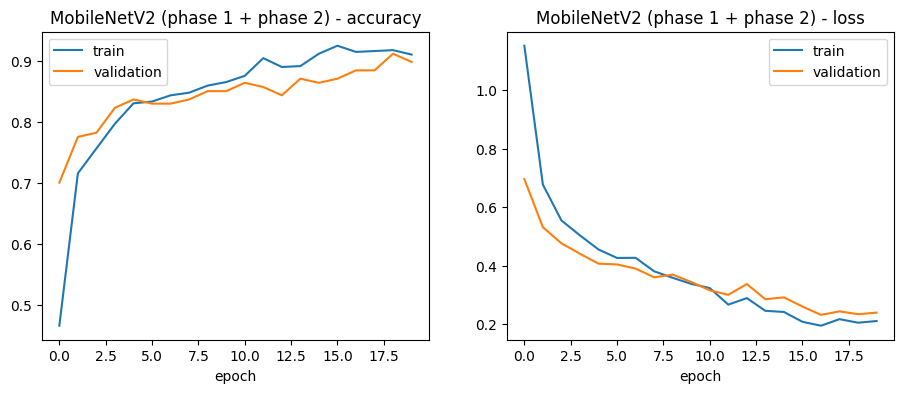

In [38]:
history = {key: phase1.history[key] + phase2.history[key] for key in phase1.history}
plot_history(history, "MobileNetV2 (phase 1 + phase 2)")

**Interpretation:**
- **Fine-tuning improved the model.** The best epoch was epoch 7, with validation loss 0.2319. Its weights were restored and kept. Compared with phase 1, loss fell from 0.345 to 0.232, accuracy rose from 85.0% to 88.4% (5 more images correct) and F1 from 0.848 to 0.884.
- We select by loss, not accuracy. Epoch 9 had a higher accuracy (91.2%), but the loss measures how confident and correct the predictions are. With 147 validation images the difference between 88% and 91% is only 4 images, so it is partly noise.
- **No over-fitting.** Training accuracy (about 89-92%) and validation accuracy (about 84-91%) stay close and both improve. Dropout, augmentation, L2 regularization and the very small learning rate are doing their job.
- The learning rate was halved only in the last epoch and the curves are flattening, so more training would give only a small gain.

In [ ]:
# Create the models folder if it does not already exist.
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 1) The full model (.keras): used by the API and for retraining.
model.save(config.MODEL_PATH)

# 2) An inference-only copy (.h5): the same model without the augmentation block.
from src.model import export_inference_model
export_inference_model(model).save(config.MODEL_H5_PATH)

for path in [config.MODEL_PATH, config.MODEL_H5_PATH]:
    print("Saved:", path, "-", round(path.stat().st_size / 1_000_000, 1), "MB")

# Check: the .h5 file must give the same predictions as the .keras model.
h5_model = keras.models.load_model(config.MODEL_H5_PATH, compile=False)
one_batch = next(iter(test_ds))[0]
same = np.allclose(model(one_batch, training=False).numpy(), h5_model(one_batch, training=False).numpy(), atol=1e-4)
print("The .h5 file gives the same predictions as the .keras model:", same)

**Interpretation:**

The final MobileNetV2 model is saved in the project folder `models/` in two files:
- `bean_model.keras` is the **full model** (with the augmentation block). The API loads it and the retraining code fine-tunes it.
- `bean_model.h5` is an **inference-only copy** without the augmentation block, which is only needed during training. The `RandomBrightness` layer cannot be saved in `.h5` format, so this copy is built from the other layers.

The printed sizes help us check that both files are small enough to store directly in GitHub, and the last line confirms that the two files give the same predictions. The folder is created automatically if it does not exist.

## 7. Evaluation on the test set

This is the **first time** the models see the test images. We never used them for training or for choosing anything, so these numbers show how the models behave on new photos. We compare the baseline CNN and the final MobileNetV2 model.

In [40]:
baseline_test = evaluate_model(baseline, test_ds, class_names)
final_test = evaluate_model(model, test_ds, class_names)

score_names = ["loss", "accuracy", "precision", "recall", "f1"]
comparison = pd.DataFrame({
    "Baseline CNN": {name: baseline_test[name] for name in score_names},
    "MobileNetV2 (final)": {name: final_test[name] for name in score_names},
})
comparison

,Baseline CNN,MobileNetV2 (final)
loss,0.9865,0.2523
accuracy,0.7124,0.8889
precision,0.7150,0.8928
recall,0.7124,0.8889
f1,0.7063,0.8897


**Interpretation:**
- **MobileNetV2 is clearly better than the baseline on unseen images.** Test accuracy is 88.9% (136 of 153 correct) versus 71.2% (109 of 153), which is +17.7 points and 27 more correct images. F1 is 0.890 versus 0.706, and the loss is 0.25 versus 0.99.
- The test accuracy (88.9%) is close to the validation accuracy (88.4%), so we did not over-tune the model to the validation set, and there is no sign of data leakage.
- The test set has only 153 images, so the real accuracy is roughly between 84% and 94%. We should not read differences of one or two points as meaningful.

### 7.1 Precision, recall and F1 for each class (final model)

In [41]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from src.model import predict_all

y_true, y_pred = predict_all(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

                   precision    recall  f1-score   support

angular_leaf_spot      0.915     0.843     0.878        51
        bean_rust      0.804     0.882     0.841        51
          healthy      0.960     0.941     0.950        51

         accuracy                          0.889       153
        macro avg      0.893     0.889     0.890       153
     weighted avg      0.893     0.889     0.890       153



**Interpretation:**
- **Healthy leaves are recognised best** (precision 0.960, recall 0.941, F1 0.950).
- **Bean rust has the lowest F1 (0.841)**, mainly because of low precision (0.804). The model predicted "rust" 56 times and was right 45 times: 8 angular leaf spot leaves and 3 healthy leaves were wrongly called rust. When unsure, the model leans towards rust.
- **Angular leaf spot has the lowest recall (0.843)**: 8 of its 51 leaves were missed, all called rust.
- Every class has 51 test images (support), so the macro average (F1 0.890) weighs the three classes equally.

### 7.2 Confusion matrices
Rows are the **true** class, columns are what the model **predicted**. The diagonal is correct predictions.

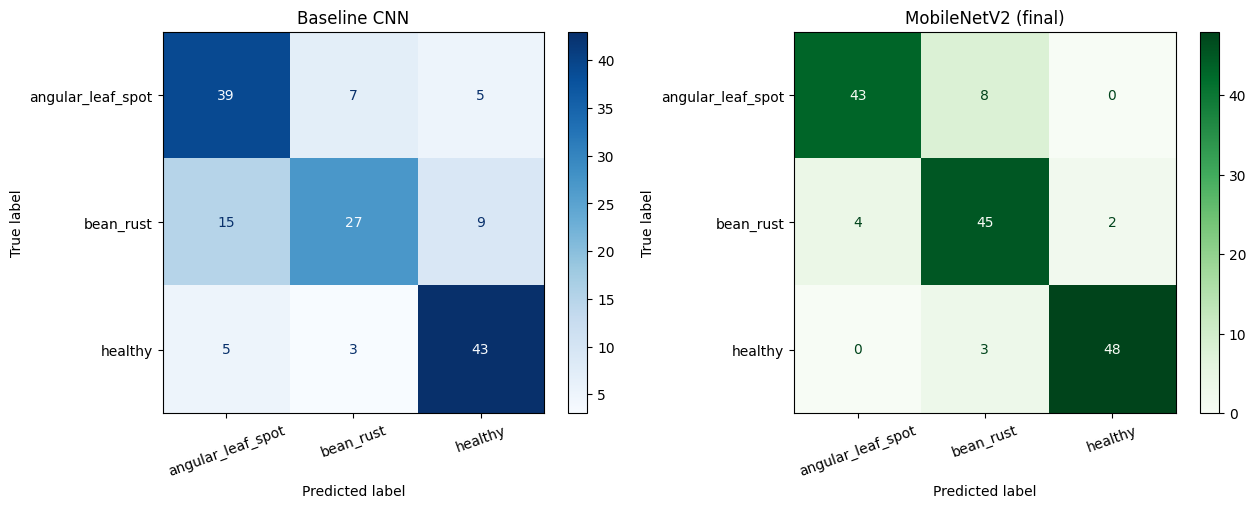

In [42]:
y_true_base, y_pred_base = predict_all(baseline, test_ds)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_true_base, y_pred_base, display_labels=class_names,
                                        cmap="Blues", xticks_rotation=20, ax=axes[0])
axes[0].set_title("Baseline CNN")
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names,
                                        cmap="Greens", xticks_rotation=20, ax=axes[1])
axes[1].set_title("MobileNetV2 (final)")
plt.tight_layout()
plt.show()

In [ ]:
print("Final model - confusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(final_test["confusion_matrix"], index=class_names, columns=class_names))

print("\nBaseline CNN:")
print(pd.DataFrame(baseline_test["confusion_matrix"], index=class_names, columns=class_names))

**Interpretation:**
- **The final model makes 17 mistakes out of 153 test images; the baseline makes 44.**
- **Most errors (12 of 17) are between the two diseases:** 8 angular leaf spot leaves predicted as rust, and 4 rust leaves predicted as angular leaf spot. No angular leaf spot leaf was called healthy, and no healthy leaf was called angular leaf spot.
- **Disease versus healthy matters most for a farmer.** Of the 102 diseased leaves, 100 were flagged as diseased (98%), and only 2 rust leaves were called healthy. The baseline called 14 diseased leaves healthy. 3 healthy leaves were wrongly flagged as rust (false alarms).
- The specific disease name is right for 88 of the 102 diseased leaves (86%), so the label should be treated as guidance and not as a final diagnosis.

### 7.3 Which images did the final model get wrong?

Wrong predictions: 17 out of 153


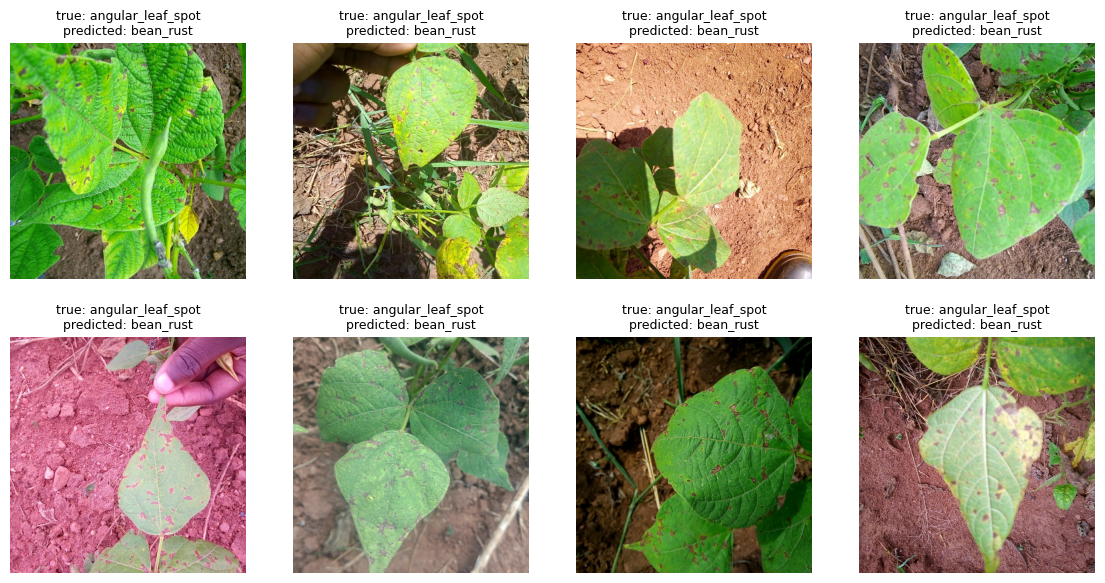

In [43]:
wrong = np.where(y_true != y_pred)[0]
print("Wrong predictions:", len(wrong), "out of", len(y_true))

plt.figure(figsize=(14, 7))
for i, index in enumerate(wrong[:8]):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(test_paths[index]))
    plt.title("true: " + class_names[y_true[index]] + "\npredicted: " + class_names[y_pred[index]], fontsize=9)
    plt.axis("off")
plt.show()

In [ ]:
# the errors that the first grid did not show
plt.figure(figsize=(12, 9))
for i, index in enumerate(wrong[8:17]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(Image.open(test_paths[index]))
    plt.title("true: " + class_names[y_true[index]] + "\npredicted: " + class_names[y_pred[index]], fontsize=9)
    plt.axis("off")
plt.show()

**Interpretation:**
- The model got 17 of 153 test images wrong. The first grid shows the first 8, and all of them are angular leaf spot leaves predicted as bean rust (the test images are ordered by class, so the first errors all come from the same class). The second grid shows the remaining errors.
- Possible reasons, not proof: the spots are small, scattered and dark brown, which looks like rust dots. Several photos are dark or shaded, one has a strong pink colour cast from the red soil, and some show many leaves at once against a busy background.
- The other 9 errors are rust leaves predicted as angular leaf spot or healthy, and healthy leaves predicted as rust.

In [ ]:
import json
from datetime import datetime

report = dict(final_test)
report["baseline_accuracy"] = baseline_test["accuracy"]
report["version"] = 1
report["note"] = "First model, trained in the notebook"
report["trained_at"] = datetime.now().isoformat(timespec="seconds")

# Make sure the model folder exists.
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save the test metrics in models/metrics.json.
with open(config.MODELS_DIR / "metrics.json", "w") as f:
    json.dump(report, f, indent=2)

print("Saved metrics.json")
print("File location:", config.MODELS_DIR / "metrics.json")

**Interpretation:**

This cell saves the final test metrics to `models/metrics.json`. It includes the final model's test results, the baseline accuracy, a version number, a short note and the time the report was created. Keeping this file beside the trained model makes it easier to record and compare model versions later.



## 8. Prediction function

`src/prediction.py` loads the saved model and classifies **one image**. The API will use this same file. If the model file changes (after retraining), it automatically loads the new one.

In [48]:
%%writefile src/prediction.py
"""Prediction: load the saved model and classify one image."""
import os
import threading

import numpy as np
from tensorflow import keras

from src.config import MODEL_PATH, load_class_names
from src.preprocessing import image_to_array, validate_image

_model = None
_model_time = None
_lock = threading.Lock()


def get_model():
    """Load the model once. If the file changes (after retraining), load the new one."""
    global _model, _model_time
    if not MODEL_PATH.exists():
        raise FileNotFoundError("Model not found. Train and save it first (run the notebook).")
    modified = os.path.getmtime(MODEL_PATH)
    if _model is None or modified != _model_time:
        with _lock:
            if _model is None or modified != _model_time:
                _model = keras.models.load_model(MODEL_PATH, compile=False)
                _model_time = modified
    return _model


def predict_image(file_bytes):
    """Takes the bytes of an image file. Returns the predicted class and all probabilities."""
    class_names = load_class_names()
    image = validate_image(file_bytes)
    probabilities = get_model()(image_to_array(image), training=False).numpy()[0]
    best = int(np.argmax(probabilities))
    return {
        "class": class_names[best],
        "confidence": round(float(probabilities[best]), 4),
        "probabilities": {name: round(float(p), 4) for name, p in zip(class_names, probabilities)},
    }

Writing src/prediction.py


**Interpretation:**

This creates `src/prediction.py`, a reusable prediction module. It loads the saved Keras model when needed, checks that an uploaded file is a valid image, applies the same resizing and preprocessing used during training, and returns the predicted class with its confidence and class probabilities. The model is cached so it is not loaded from disk for every prediction request.



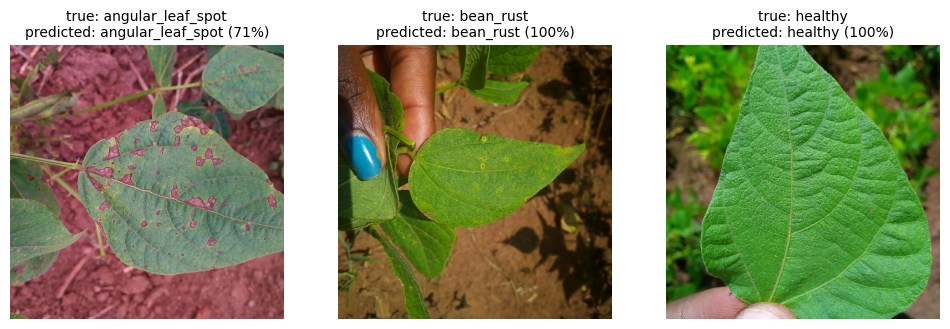

In [49]:
from src.prediction import predict_image

plt.figure(figsize=(12, 4))
for i, class_name in enumerate(class_names):
    folder = config.DATA_DIR / "test" / class_name
    path = folder / sorted(os.listdir(folder))[0]

    with open(path, "rb") as f:
        result = predict_image(f.read())

    plt.subplot(1, 3, i + 1)
    plt.imshow(Image.open(path))
    plt.axis("off")
    plt.title(f"true: {class_name}\npredicted: {result['class']} ({result['confidence']:.0%})", fontsize=10)
plt.show()

**Interpretation:**

The prediction function works end to end from the saved model: it classified one test leaf from each class correctly. The angular leaf spot leaf got a lower confidence (71%) than the rust and healthy leaves (100%). Confidence is the model's own estimate and not a guarantee, since the model still gets about 11% of the test images wrong. In the app we will show all class probabilities and advise users to consult an extension officer when the confidence is low.

## 9. Conclusion and limitations

**What we built:** a complete image-classification pipeline for bean leaf disease: data cleaning and a stratified train / validation / test split, reusable preprocessing code in `src/`, a baseline CNN, and a MobileNetV2 transfer-learning model with data augmentation, dropout, L2 regularization, early stopping, learning-rate reduction and fine-tuning.

**Results (test set, 153 images):** the final model reaches about 89% accuracy and an F1 score of about 0.89, compared with about 71% for the baseline CNN. The most common mistake is confusing the two diseases with each other (mostly angular leaf spot called bean rust). A diseased leaf is rarely called healthy.

**Limitations**
- The test set is small (51 images per class), so every score has an uncertainty of roughly 5 points.
- All photos come from one dataset. Photos taken by farmers with other phones, lighting and backgrounds may give lower accuracy, and the background (soil, hands, other leaves) may help the model in ways that will not hold elsewhere.
- The model is a screening aid. It does not replace an expert diagnosis.

**Next parts of the project:** store uploaded images in a database, retrain the model from the saved `bean_model.keras` file, serve predictions through an API (`src/api.py`) and build the web UI.

## 10. Push the generated files to GitHub (Kaggle only)

Run the next cell last, after the notebook has created the files in `src/` and saved the models in `models/`. It stages the source files, the models, the class labels and the project configuration, but **does not stage this notebook** or the dataset split folders.

It needs a Kaggle secret named `GITHUB_TOKEN`: a fine-grained GitHub token with *Contents: read and write* permission for this one repository (*Add-ons, then Secrets*). The token is removed from the Git remote again at the end. **If this cell shows an error, clear its output before saving the notebook.**

**GitHub file-size note:** GitHub blocks files larger than 100 MB. The printed model sizes are far below this.

On your laptop, skip this cell and use `git pull`, `git add`, `git commit` and `git push` in the terminal.

In [ ]:
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("GITHUB_TOKEN")
!git remote set-url origin https://{token}@github.com/Jonathan2055/BeanGuardAI.git

!git config --global user.email "j.mugisha3@alustudent.com"
!git config --global user.name "Jonathan2055"

# Add source files, class labels and project configuration (the notebook and the split folders are not included).
!git add src/ data/class_names.json README.md requirements.txt .gitignore

# Add the saved models even if .gitignore contains a models/ rule.
!git add -f models/

!git status
!git commit -m "Update models, metrics and source files from the notebook"
!git push origin main

# Remove the token from the remote URL again.
!git remote set-url origin https://github.com/Jonathan2055/BeanGuardAI.git